In [2]:
import torch
import torch.nn as nn
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, DDPMScheduler, ControlNetModel
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
import pandas as pd
from torchvision import transforms
import nibabel as nib
from tqdm.auto import tqdm

# --- ローカルGPUの設定 ---
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


In [3]:
# ===================================================================
# 学習時と全く同じモデルクラス（CustomConditionalLDM）を再定義
# ===================================================================
class CustomConditionalLDM(nn.Module):
    # (02_model_training.ipynbで使った【最終決定版】のクラス定義をここにコピー＆ペースト)
    def __init__(self, pretrained_model_name="runwayml/stable-diffusion-v1-5"):
        super().__init__()
        self.vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae")
        self.tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
        self.text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder")
        self.unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet")
        self.scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
        self.controlnet = ControlNetModel.from_config(self.unet.config)
        
        in_channels = 4
        out_channels = self.controlnet.conv_in.out_channels
        self.controlnet.controlnet_cond_embedding = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.SiLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
        )
        for module in self.controlnet.controlnet_cond_embedding.modules():
            if isinstance(module, nn.Conv2d):
                torch.nn.init.zeros_(module.weight)
                torch.nn.init.zeros_(module.bias)

        self.vae.requires_grad_(False)
        self.text_encoder.requires_grad_(False)
        self.unet.requires_grad_(False)

In [4]:
# ===================================================================
# 推論用に修正したデータセットクラスを再定義
# ===================================================================
class BrainMetsDataset(Dataset):
    """
    推論用に、ベースライン画像とファイル名だけを読み込むクラス。
    """
    def __init__(self, csv_file, image_root_dir, patient_ids, mode, image_size=256, latent_size=32):
        self.data = pd.read_csv(csv_file)
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        
        self.image_root_dir = image_root_dir
        self.mode = mode
        self.image_size = image_size
        self.scans = self._get_scans()
        
        # 画像の前処理レシピ
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((self.image_size, self.image_size), antialias=True),
            transforms.Normalize([0.5], [0.5])
        ])

    def _get_scans(self):
        scans = []
        # ベースライン画像の情報だけをリストアップする
        baseline_scans = self.data[self.data['FinalPattern'] == 'Baseline']
        for _, baseline_row in baseline_scans.iterrows():
            scans.append(baseline_row.to_dict())
        print(f"Found {len(scans)} baseline images for '{self.mode}' set.")
        return scans

    def __len__(self):
        return len(self.scans)

    def __getitem__(self, idx):
        scan_info = self.scans[idx]
        baseline_filename = scan_info['FileName'] # マスクと突合するための元のファイル名
        
        # 画像ファイルパス（_0000.nii.gz が付く）
        base_name_without_ext = baseline_filename.replace('.nii.gz', '')
        filename_with_suffix = f"{base_name_without_ext}_0000.nii.gz"
        path = os.path.join(self.image_root_dir, filename_with_suffix)
        
        try:
            # --- 画像の読み込みと正しい正規化 ---
            nii_img = nib.load(path)
            data = nii_img.get_fdata().astype('float32')
            slice_img = data[:, :, data.shape[2] // 2]
            if slice_img.max() > slice_img.min():
                slice_img = (slice_img - slice_img.min()) / (slice_img.max() - slice_img.min())
            
            image = self.transform(slice_img).repeat(3, 1, 1)
            
            # 💡 ファイル名も返す
            return {"baseline_image": image, "patient_id": scan_info['PatientID'], "filename": baseline_filename}
        
        except FileNotFoundError as e:
            print(f"Warning: File not found ({e}). Skipping this scan.")
            return self.__getitem__((idx + 1) % len(self))

In [5]:
# ===================================================================
# 1. モデルのインスタンス化と重みの読み込み
# ===================================================================
print("Initializing the model structure...")
model = CustomConditionalLDM().to(device)

# --- ★★★ ここが最重要 ★★★ ---
# 学習したControlNetの「最高の重み」を読み込む
CONTROLNET_WEIGHTS_PATH = '/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ10/best_model_epoch_147.pth'
model.controlnet.load_state_dict(torch.load(CONTROLNET_WEIGHTS_PATH, map_location=device))
model.eval() # モデルを推論モードに設定

print(f"✅ Best model weights loaded from: {CONTROLNET_WEIGHTS_PATH}")

# ===================================================================
# 2. テストデータの準備
# ===================================================================
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
full_df = pd.read_csv(CSV_FILE)
patient_ids = full_df['PatientID'].unique()
# 学習時と全く同じ random_state を使うことで、同じ患者がテスト用に選ばれる
_, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
_, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

# --- テストデータローダーを作成 ---
test_dataset = BrainMetsDataset(csv_file=CSV_FILE, image_root_dir=IMAGE_DIR, patient_ids=test_patient_ids, mode='test')
test_dataloader = DataLoader(test_dataset, batch_size=1, shuffle=True)

# --- テストデータを1つランダムに取得 ---
sample_batch = next(iter(test_dataloader))
baseline_image = sample_batch["baseline_image"].to(device)
patient_id = sample_batch["patient_id"][0]
baseline_filename = sample_batch["filename"][0] # マスク表示に使うファイル名

print(f"\nLoaded baseline image for patient: {patient_id} (File: {baseline_filename})")

Initializing the model structure...


/tmp/ipykernel_1953122/3209816711.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.controlnet.load_state_dict(torch.load(CONTROLNET_WEIGHTS_PATH, map_location=devi

✅ Best model weights loaded from: /home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ10/best_model_epoch_147.pth
Found 205 baseline images for 'test' set.

Loaded baseline image for patient: YG_83ATT6753PYK (File: YG_83ATT6753PYK_2019-11-08_08-27-32.nii.gz)



Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]


✅ Segmentation mask loaded for visualization.


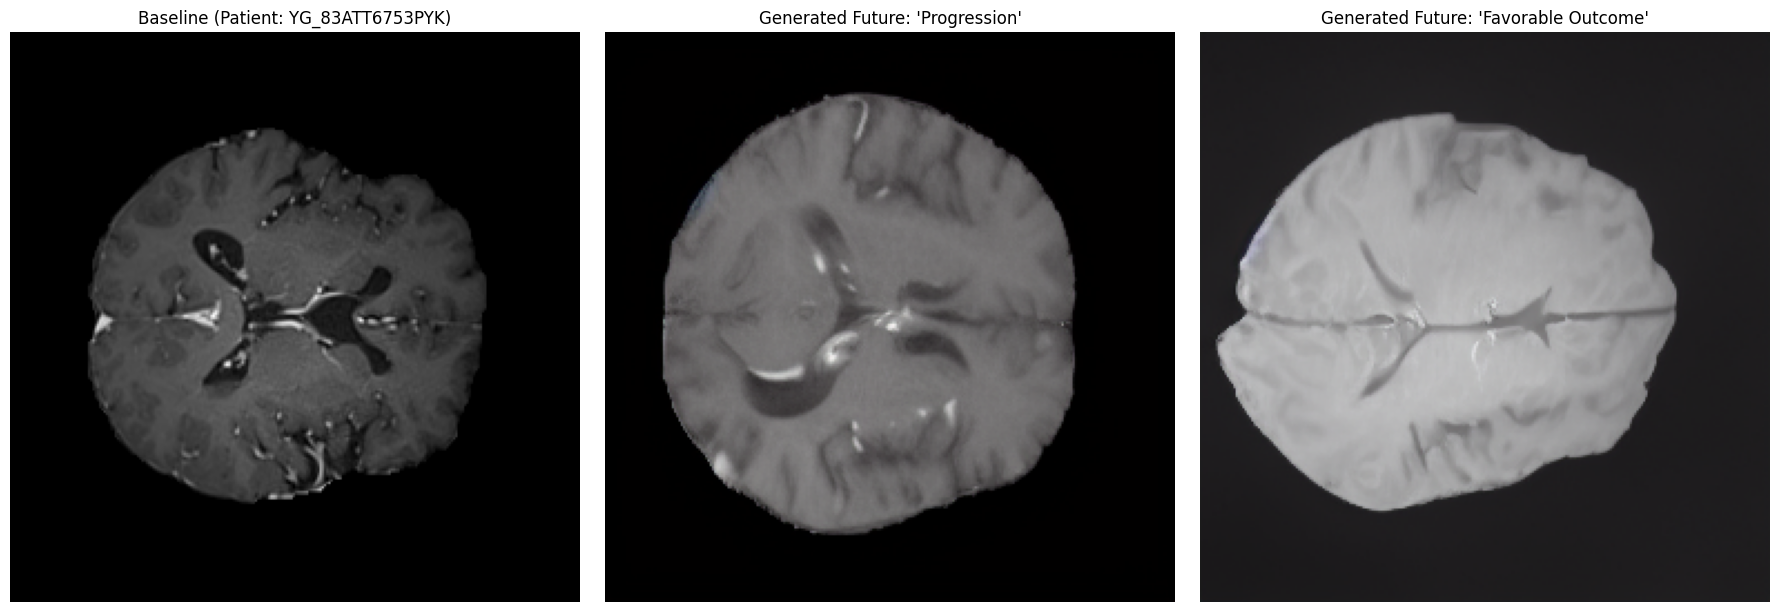

In [6]:
# ===================================================================
# 推論（画像生成）を行う関数
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    """
    与えられたベースライン画像と条件から、未来の画像を生成する関数。
    """
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    # ノイズ除去ループ
    for t in tqdm(model.scheduler.timesteps, desc=f"Denoising ({condition_label})"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    # VAEで最終的な画像を復元
    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image = model.vae.decode(latents).sample
        
    # PIL.Image形式に変換
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# --- 2つの条件で画像を生成 ---
progression_image = generate_future_image(model, baseline_image, "Progression")
favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")

# ===================================================================
# 結果の可視化（セグメンテーションマスクを重ねて表示）
# ===================================================================
# --- 1. 対応するセグメンテーションマスクを読み込む ---
SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
seg_path = os.path.join(SEG_DIR, baseline_filename) # _0000が付いていないファイル名

seg_mask_rgba = None
try:
    seg_nii = nib.load(seg_path)
    seg_data = seg_nii.get_fdata().astype('float32')
    seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
    # マスクを256x256にリサイズ
    seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
    seg_mask = np.array(seg_slice_pil)
    # 腫瘍部分(>0)を半透明の赤色にするRGBAマスクを作成
    seg_mask_rgba = np.zeros((256, 256, 4))
    seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%の透明度
    print("\n✅ Segmentation mask loaded for visualization.")
except FileNotFoundError:
    print(f"\n⚠️ Warning: Segmentation mask not found at {seg_path}")

# --- 2. 3枚の画像を並べて表示 ---
def to_pil(tensor_image):
    # Tensor画像をPIL画像に変換するヘルパー関数
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

plt.figure(figsize=(18, 6))

# --- ベースライン + マスク ---
plt.subplot(1, 3, 1)
plt.imshow(to_pil(baseline_image), cmap='gray')
if seg_mask_rgba is not None:
    plt.imshow(seg_mask_rgba) # マスクを重ねる
plt.title(f"Baseline (Patient: {patient_id})")
plt.axis('off')

# --- Progression ---
plt.subplot(1, 3, 2)
plt.imshow(progression_image, cmap='gray')
plt.title("Generated Future: 'Progression'")
plt.axis('off')

# --- Favorable Outcome ---
plt.subplot(1, 3, 3)
plt.imshow(favorable_image, cmap='gray')
plt.title("Generated Future: 'Favorable Outcome'")
plt.axis('off')

plt.tight_layout()
plt.show()


--- Processing sample 1/3 for patient: YG_FJU827WUPDO9 ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


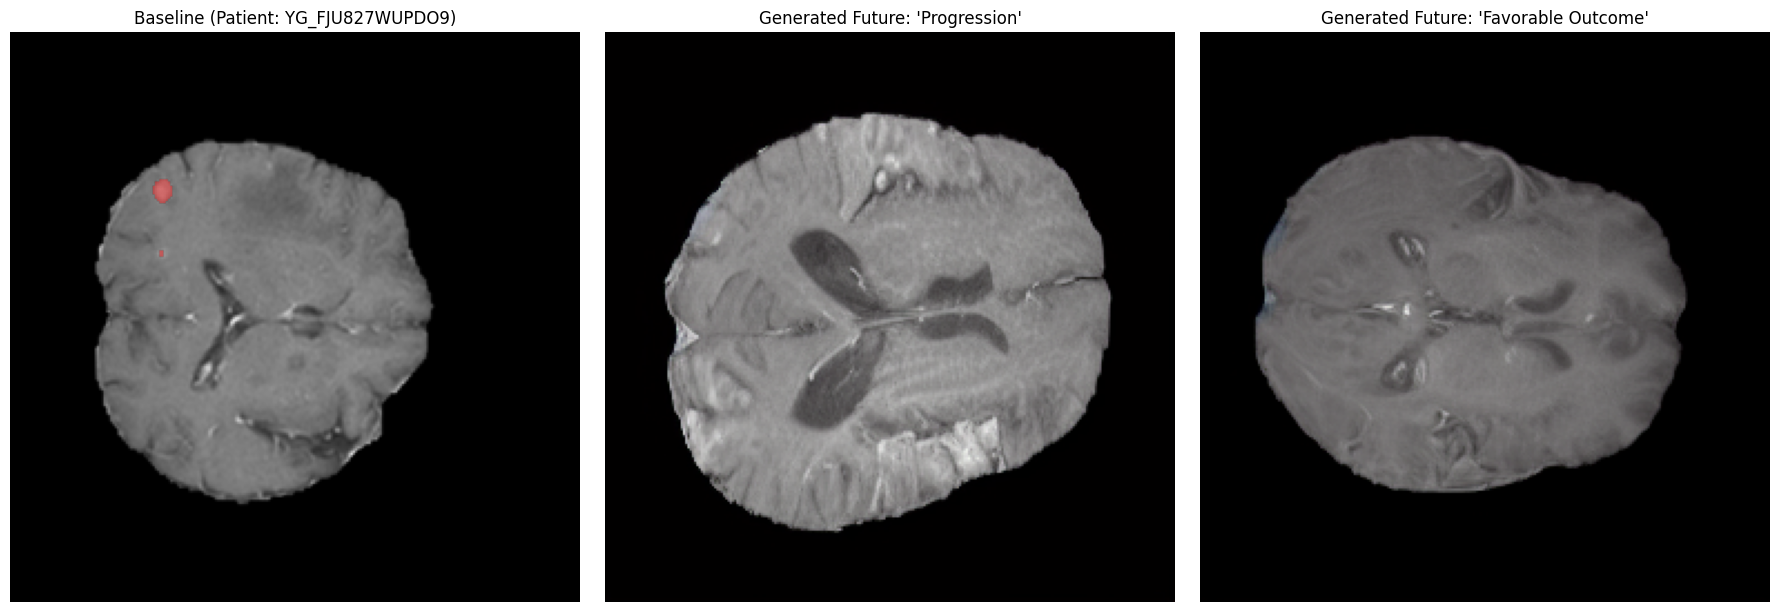


--- Processing sample 2/3 for patient: YG_Q7D6O0EB0GA5 ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


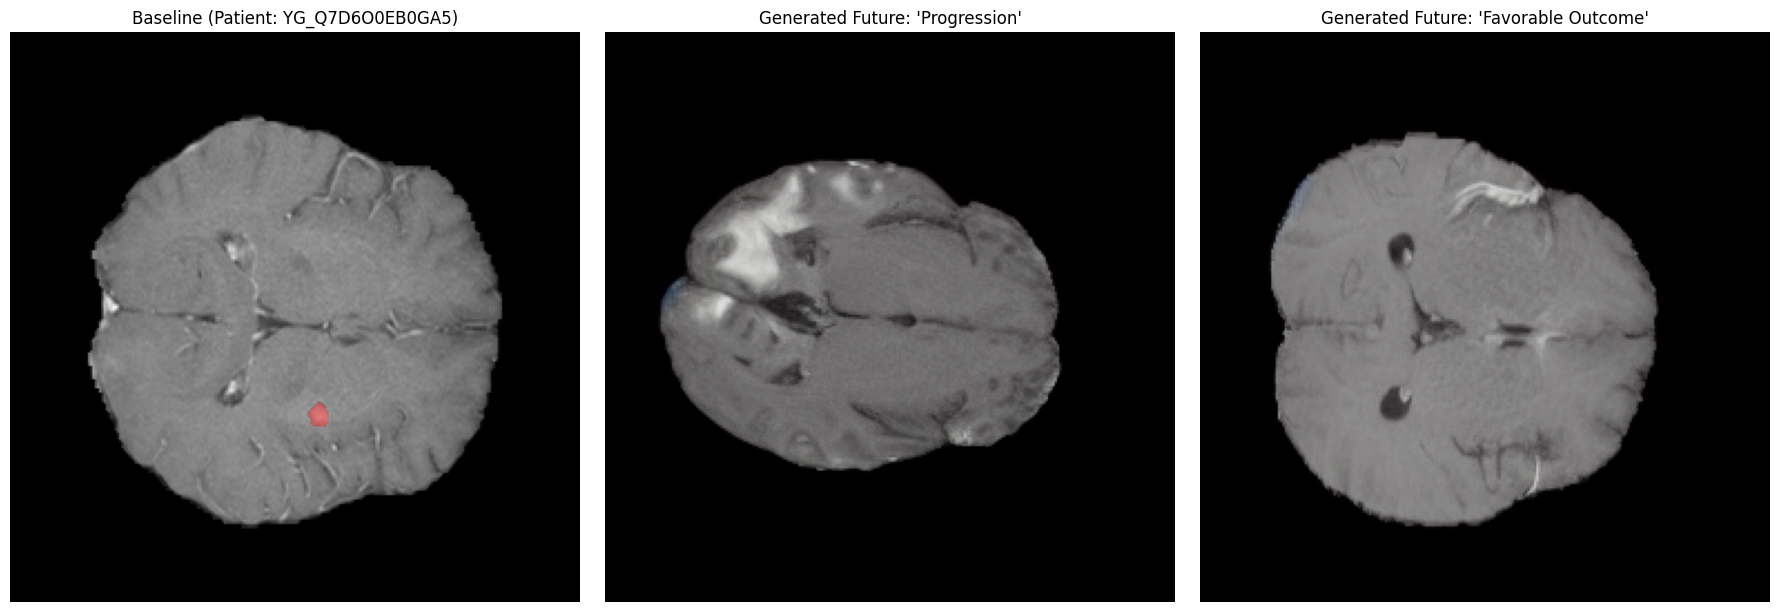


--- Processing sample 3/3 for patient: YG_S5QZ8B8BQK30 ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


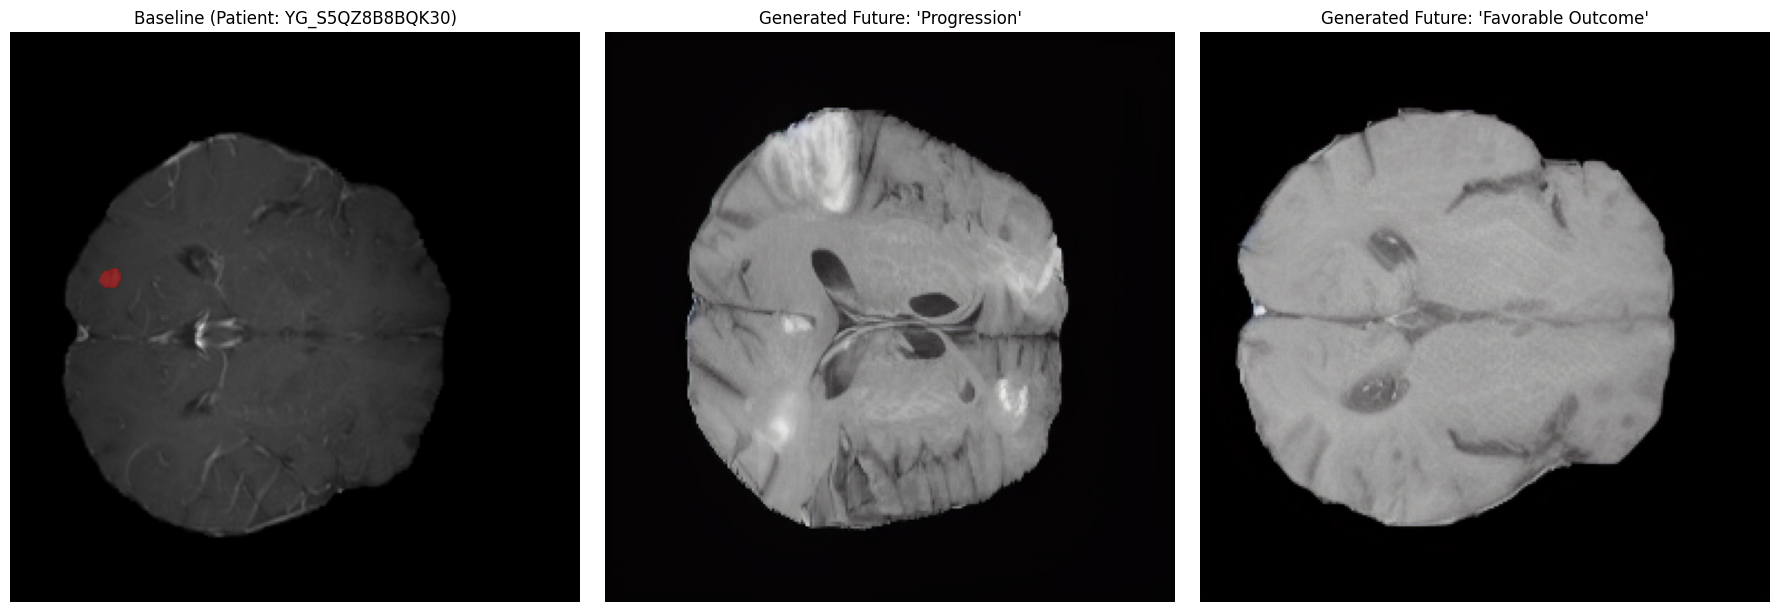


🎉 All 3 samples processed! 🎉


In [8]:
import torch # 念のため、必要なライブラリをインポート
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import nibabel as nib
import os

# ===================================================================
# 推論（画像生成）を行う関数
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    """
    与えられたベースライン画像と条件から、未来の画像を生成する関数。
    """
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    # ノイズ除去ループ
    for t in tqdm(model.scheduler.timesteps, desc=f"Denoising ({condition_label})"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    # VAEで最終的な画像を復元
    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image = model.vae.decode(latents).sample
        
    # PIL.Image形式に変換
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# ===================================================================
# Tensor画像をPIL画像に変換するヘルパー関数
# ===================================================================
def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

# ===================================================================
# ★★★ ここからが修正点 ★★★
# 3人分の結果をループで生成・可視化
# ===================================================================
NUM_SAMPLES_TO_SHOW = 3 # 表示したい患者の人数

# test_dataloaderから指定した人数分のデータを取得
# (test_dataloader, device, model は前のセルで定義済みと仮定)
for i, sample_batch in enumerate(test_dataloader):
    if i >= NUM_SAMPLES_TO_SHOW:
        break # 3人分処理したらループを終了

    # --- 1. データを準備 ---
    baseline_image = sample_batch["baseline_image"].to(device)
    patient_id = sample_batch["patient_id"][0]
    baseline_filename = sample_batch["filename"][0]
    print(f"\n--- Processing sample {i+1}/{NUM_SAMPLES_TO_SHOW} for patient: {patient_id} ---")

    # --- 2. 2つの条件で画像を生成 ---
    progression_image = generate_future_image(model, baseline_image, "Progression")
    favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")
    
    # --- 3. 対応するセグメンテーションマスクを読み込む ---
    SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
    seg_path = os.path.join(SEG_DIR, baseline_filename) # _0000が付いていないファイル名
    
    seg_mask_rgba = None
    try:
        seg_nii = nib.load(seg_path)
        seg_data = seg_nii.get_fdata().astype('float32')
        seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
        seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
        seg_mask = np.array(seg_slice_pil)
        seg_mask_rgba = np.zeros((256, 256, 4))
        seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%の透明度
        print("✅ Segmentation mask loaded for visualization.")
    except FileNotFoundError:
        print(f"⚠️ Warning: Segmentation mask not found at {seg_path}")

    # --- 4. 3枚の画像を並べて表示 ---
    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(to_pil(baseline_image), cmap='gray')
    if seg_mask_rgba is not None:
        plt.imshow(seg_mask_rgba)
    plt.title(f"Baseline (Patient: {patient_id})")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(progression_image, cmap='gray')
    plt.title("Generated Future: 'Progression'")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(favorable_image, cmap='gray')
    plt.title("Generated Future: 'Favorable Outcome'")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

print(f"\n🎉 All {NUM_SAMPLES_TO_SHOW} samples processed! 🎉")


--- Processing sample 1/3 for patient: YG_FJU827WUPDO9 ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


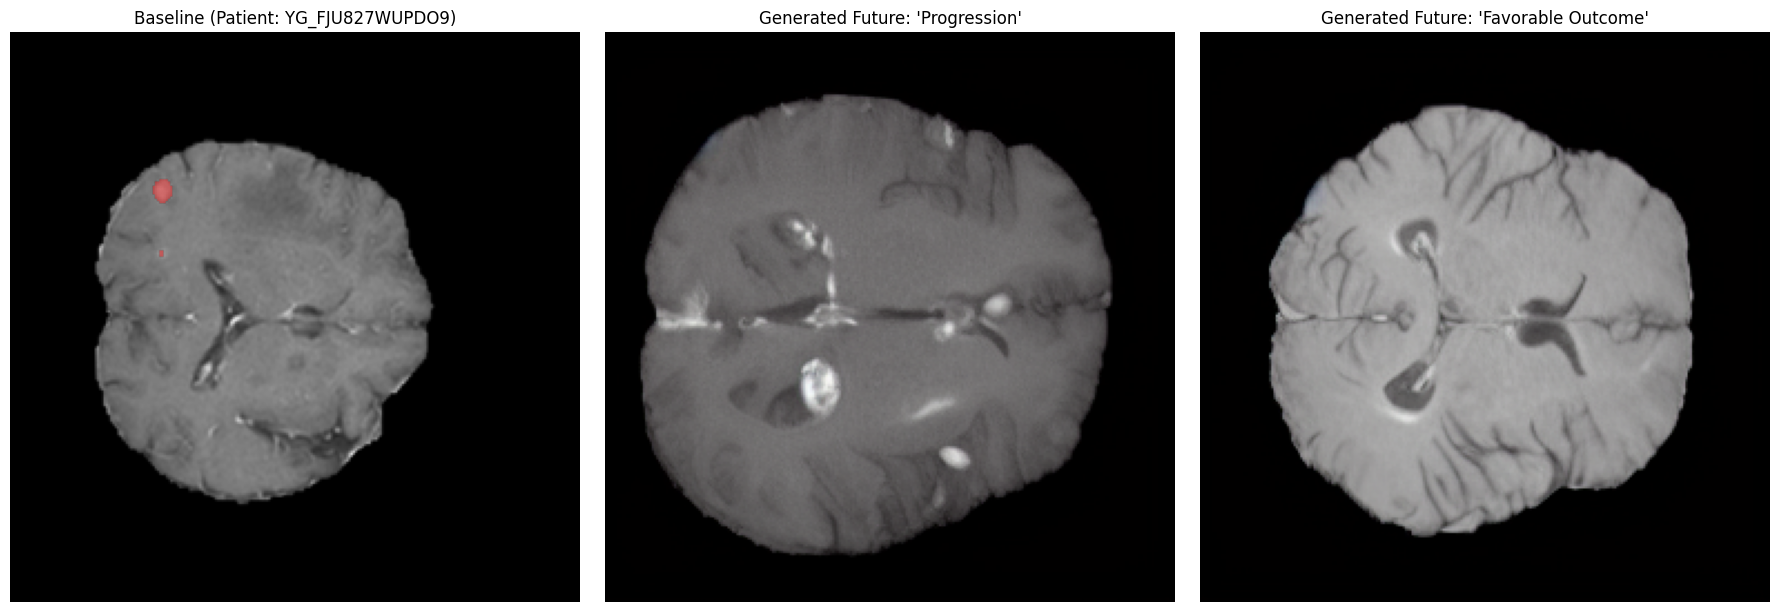


--- Processing sample 2/3 for patient: YG_W0LASFIJHMPP ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


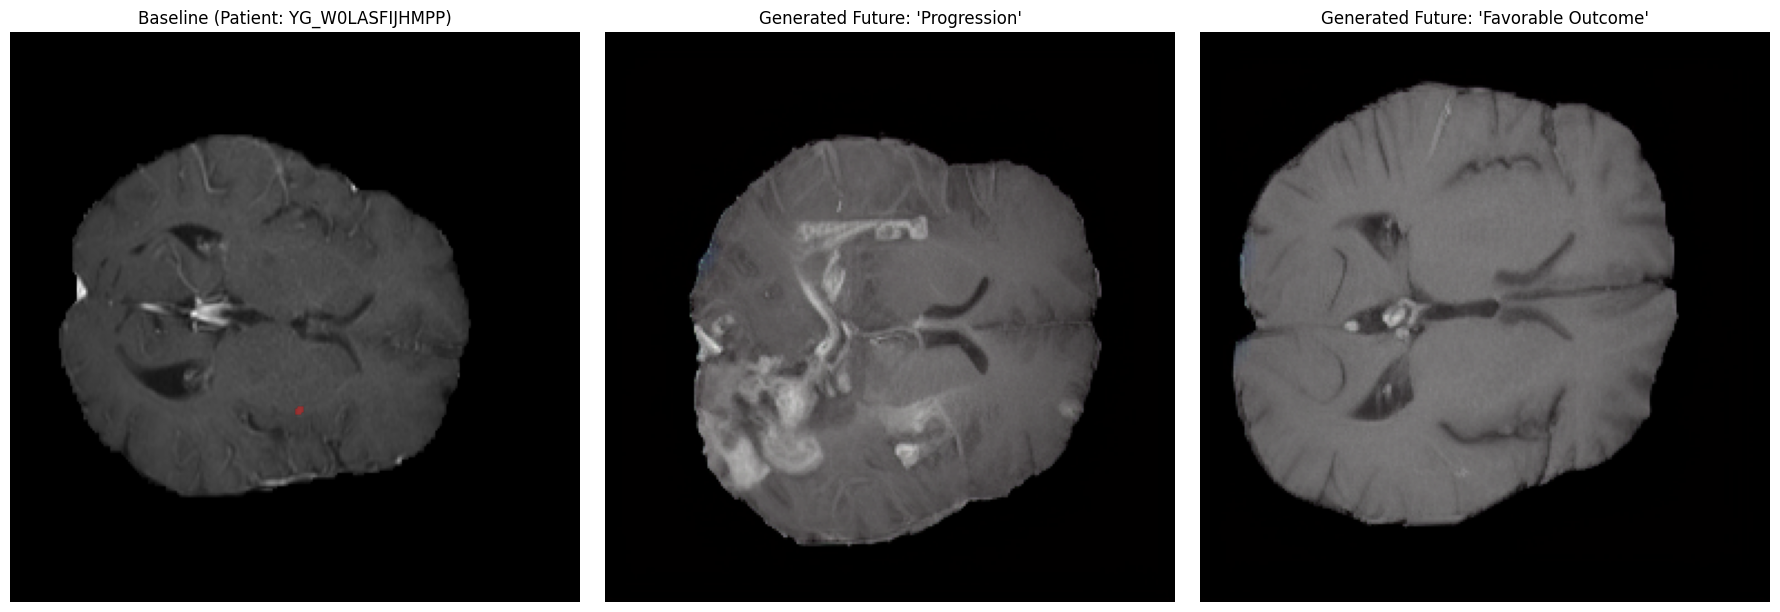


--- Processing sample 3/3 for patient: YG_TQMEV76VPUJP ---

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable_Outcome'...


Denoising (Favorable_Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

✅ Segmentation mask loaded for visualization.


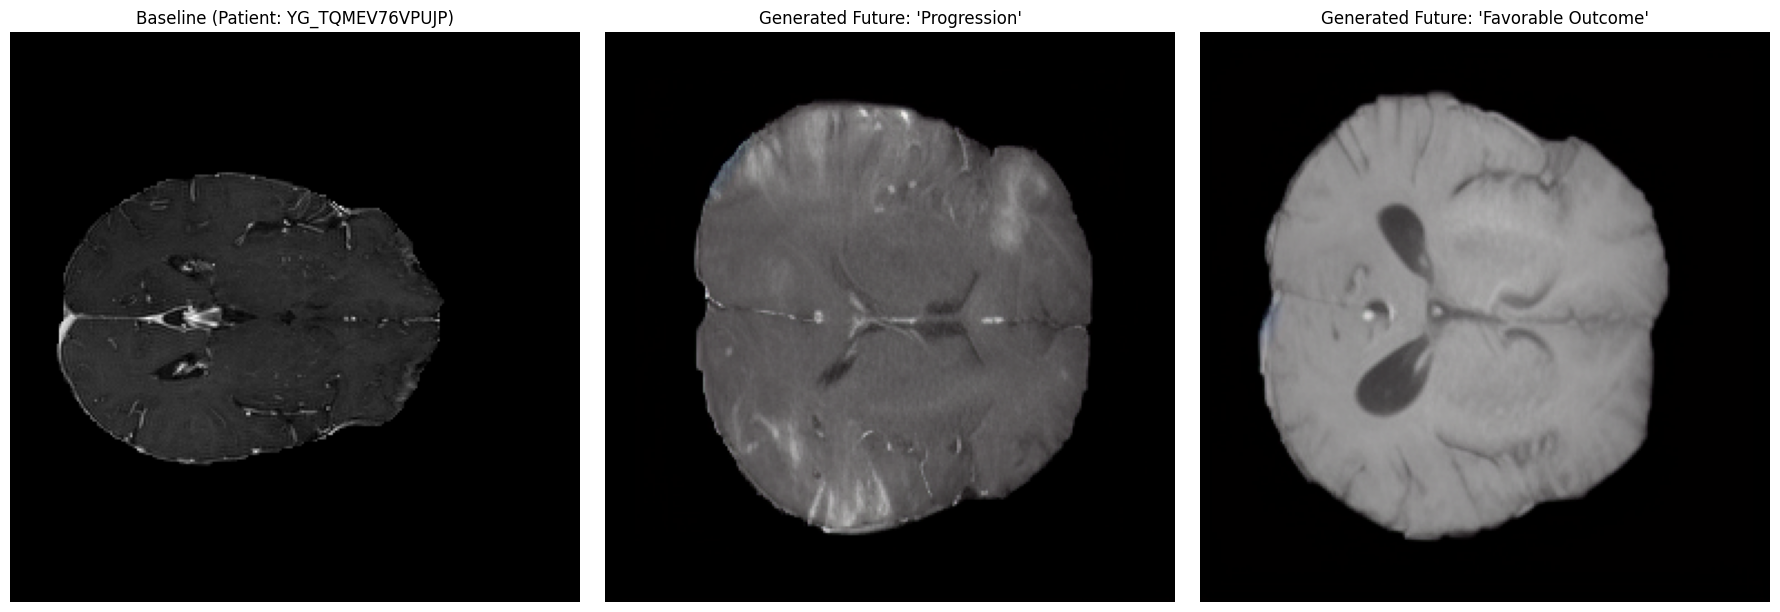


🎉 All 3 samples processed! 🎉


In [9]:
import torch # 念のため、必要なライブラリをインポート
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
import nibabel as nib
import os

# ===================================================================
# 推論（画像生成）を行う関数
# ===================================================================
def generate_future_image(model, baseline_image, condition_label, num_inference_steps=50):
    """
    与えられたベースライン画像と条件から、未来の画像を生成する関数。
    """
    print(f"\nGenerating future image for condition: '{condition_label}'...")
    
    with torch.no_grad():
        baseline_latents = model.vae.encode(baseline_image).latent_dist.sample() * model.vae.config.scaling_factor
        text_input = model.tokenizer(condition_label, padding="max_length", max_length=model.tokenizer.model_max_length, return_tensors="pt")
        text_embeddings = model.text_encoder(text_input.input_ids.to(device))[0]

    model.scheduler.set_timesteps(num_inference_steps)
    latents = torch.randn_like(baseline_latents)

    # ノイズ除去ループ
    for t in tqdm(model.scheduler.timesteps, desc=f"Denoising ({condition_label})"):
        with torch.no_grad():
            down_block_res_samples, mid_block_res_sample = model.controlnet(
                latents, t, encoder_hidden_states=text_embeddings, controlnet_cond=baseline_latents, return_dict=False
            )
            noise_pred = model.unet(
                latents, t, encoder_hidden_states=text_embeddings, down_block_additional_residuals=down_block_res_samples, mid_block_additional_residual=mid_block_res_sample
            ).sample
        
        latents = model.scheduler.step(noise_pred, t, latents).prev_sample

    # VAEで最終的な画像を復元
    with torch.no_grad():
        latents = 1 / model.vae.config.scaling_factor * latents
        image = model.vae.decode(latents).sample
        
    # PIL.Image形式に変換
    image = (image / 2 + 0.5).clamp(0, 1)
    image = image.cpu().permute(0, 2, 3, 1).numpy()[0]
    image = (image * 255).round().astype("uint8")
    return Image.fromarray(image)

# ===================================================================
# Tensor画像をPIL画像に変換するヘルパー関数
# ===================================================================
def to_pil(tensor_image):
    img = (tensor_image / 2 + 0.5).clamp(0, 1)
    img = img.cpu().permute(0, 2, 3, 1).numpy()[0]
    img = (img * 255).round().astype("uint8")
    return Image.fromarray(img)

# ===================================================================
# ★★★ ここからが修正点 ★★★
# 3人分の結果をループで生成・可視化
# ===================================================================
NUM_SAMPLES_TO_SHOW = 3 # 表示したい患者の人数

# test_dataloaderから指定した人数分のデータを取得
# (test_dataloader, device, model は前のセルで定義済みと仮定)
for i, sample_batch in enumerate(test_dataloader):
    if i >= NUM_SAMPLES_TO_SHOW:
        break # 3人分処理したらループを終了

    # --- 1. データを準備 ---
    baseline_image = sample_batch["baseline_image"].to(device)
    patient_id = sample_batch["patient_id"][0]
    baseline_filename = sample_batch["filename"][0]
    print(f"\n--- Processing sample {i+1}/{NUM_SAMPLES_TO_SHOW} for patient: {patient_id} ---")

    # --- 2. 2つの条件で画像を生成 ---
    progression_image = generate_future_image(model, baseline_image, "Progression")
    favorable_image = generate_future_image(model, baseline_image, "Favorable_Outcome")
    
    # --- 3. 対応するセグメンテーションマスクを読み込む ---
    SEG_DIR = '/home/masaki/mystudy/my_yale_data/yale_brain_mets_segmentations'
    seg_path = os.path.join(SEG_DIR, baseline_filename) # _0000が付いていないファイル名
    
    seg_mask_rgba = None
    try:
        seg_nii = nib.load(seg_path)
        seg_data = seg_nii.get_fdata().astype('float32')
        seg_slice = seg_data[:, :, seg_data.shape[2] // 2]
        seg_slice_pil = Image.fromarray(seg_slice).resize((256, 256), Image.NEAREST)
        seg_mask = np.array(seg_slice_pil)
        seg_mask_rgba = np.zeros((256, 256, 4))
        seg_mask_rgba[seg_mask > 0] = [1, 0, 0, 0.4] # 赤色, 40%の透明度
        print("✅ Segmentation mask loaded for visualization.")
    except FileNotFoundError:
        print(f"⚠️ Warning: Segmentation mask not found at {seg_path}")

    # --- 4. 3枚の画像を並べて表示 ---
    plt.figure(figsize=(18, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(to_pil(baseline_image), cmap='gray')
    if seg_mask_rgba is not None:
        plt.imshow(seg_mask_rgba)
    plt.title(f"Baseline (Patient: {patient_id})")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(progression_image, cmap='gray')
    plt.title("Generated Future: 'Progression'")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(favorable_image, cmap='gray')
    plt.title("Generated Future: 'Favorable Outcome'")
    plt.axis('off')

    plt.tight_layout()
    plt.show()

print(f"\n🎉 All {NUM_SAMPLES_TO_SHOW} samples processed! 🎉")

Searching for target patients in the dataloader...
Found patient: YG_2JKYOFLC5W1F
Found patient: YG_QF6DWVNKL4UA
Found patient: YG_TQMEV76VPUJP

Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable Outcome'...


Denoising (Favorable Outcome):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]

... (3 outputs left out)

Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable Outcome'...


Denoising (Favorable Outcome):   0%|          | 0/50 [00:00<?, ?it/s]


✅ Figure successfully saved to ./paper_figures/Fig3_with_GroundTruth.eps


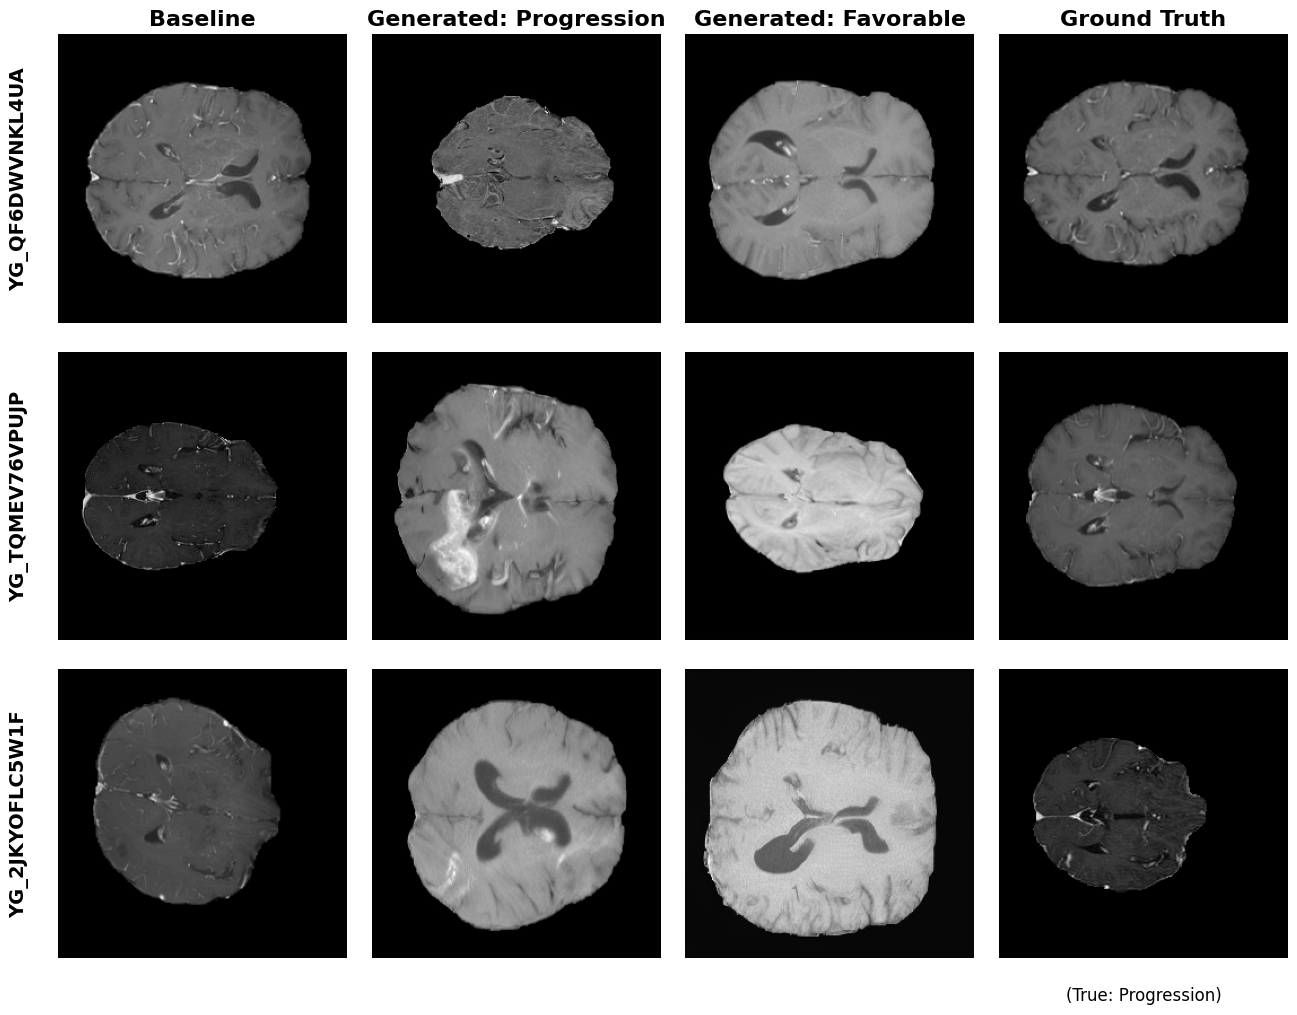

In [8]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
import nibabel as nib
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

# ===================================================================
# 1. 設定とデータローダーの再構築（Ground Truth取得用）
# ===================================================================
device = "cuda" if torch.cuda.is_available() else "cpu"
CSV_FILE = '/home/masaki/mystudy/my_yale_data/final_labeled_data.csv'
IMAGE_DIR = '/home/masaki/mystudy/my_yale_data/yale_t1post_raw'

# 表示したい患者IDのリスト（縦に並べる順序）
TARGET_PATIENT_IDS = [
    "YG_QF6DWVNKL4UA",
    "YG_TQMEV76VPUJP",
    "YG_2JKYOFLC5W1F"
]

SAVE_DIR = "./paper_figures"
os.makedirs(SAVE_DIR, exist_ok=True)
SAVE_PATH = os.path.join(SAVE_DIR, "Fig3_with_GroundTruth.eps")

# テストデータ分割の完全再現（Leakage防止）
full_df = pd.read_csv(CSV_FILE)
patient_ids = full_df['PatientID'].unique()
_, temp_patient_ids = train_test_split(patient_ids, test_size=0.3, random_state=42)
_, test_patient_ids = train_test_split(temp_patient_ids, test_size=0.5, random_state=42)

# ★正解画像（future_image）も一緒に読み込めるようにデータセットを再定義
class BrainMetsDatasetWithGT(Dataset):
    def __init__(self, csv_file, image_root_dir, patient_ids, image_size=256):
        self.data = pd.read_csv(csv_file)
        self.data = self.data[self.data['PatientID'].isin(patient_ids)]
        self.image_root_dir = image_root_dir
        self.image_size = image_size
        self.pairs = self._create_pairs()
        
        self.transform = transforms.Compose([
            transforms.ToTensor(),
            transforms.Resize((self.image_size, self.image_size), antialias=True),
            transforms.Normalize([0.5], [0.5])
        ])

    def _create_pairs(self):
        pairs = []
        for _, group in self.data.groupby('PatientID'):
            baseline_scans = group[group['FinalPattern'] == 'Baseline']
            future_scans = group[group['FinalPattern'] != 'Baseline']
            if baseline_scans.empty or future_scans.empty: continue
            for _, baseline_row in baseline_scans.iterrows():
                for _, future_row in future_scans.iterrows():
                    pairs.append({
                        "baseline_file": baseline_row['FileName'],
                        "future_file": future_row['FileName'],
                        "condition": future_row['FinalPattern']
                    })
        return pairs

    def __len__(self): return len(self.pairs)

    def __getitem__(self, idx):
        pair = self.pairs[idx]
        baseline_path = self._get_full_path(self.image_root_dir, pair['baseline_file'])
        future_path = self._get_full_path(self.image_root_dir, pair['future_file'])

        return {
            "baseline_image": self._load_and_process_image(baseline_path),
            "future_image": self._load_and_process_image(future_path),
            "condition_label": pair['condition'],
            "baseline_filename": pair['baseline_file']
        }
            
    def _get_full_path(self, directory, filename):
        name_without_ext = filename.replace('.nii.gz', '')
        return os.path.join(directory, f"{name_without_ext}_0000.nii.gz")

    def _load_and_process_image(self, path):
        nii = nib.load(path)
        data = nii.get_fdata().astype('float32')
        slice_img = data[:, :, data.shape[2] // 2]
        if slice_img.max() > slice_img.min():
            slice_img = (slice_img - slice_img.min()) / (slice_img.max() - slice_img.min())
        return self.transform(slice_img).repeat(3, 1, 1)

# 正解データ付きの新しいデータローダーの作成
test_dataloader_gt = DataLoader(BrainMetsDatasetWithGT(CSV_FILE, IMAGE_DIR, test_patient_ids), batch_size=1, shuffle=False)

# ===================================================================
# 2. 論文用図（Fig.3）の生成と保存
# ===================================================================
fig, axes = plt.subplots(nrows=len(TARGET_PATIENT_IDS), ncols=4, figsize=(16, 4 * len(TARGET_PATIENT_IDS)))
patient_data = {}

print("Searching for target patients in the dataloader...")
for batch in test_dataloader_gt:
    filename = batch["baseline_filename"][0]
    condition = batch["condition_label"][0]
    
    for pid in TARGET_PATIENT_IDS:
        if pid in filename and pid not in patient_data:
            patient_data[pid] = {
                "baseline_image": batch["baseline_image"].to(device),
                "future_image": batch["future_image"].to(device),
                "condition": condition
            }
            print(f"Found patient: {pid}")
            break
            
    if len(patient_data) == len(TARGET_PATIENT_IDS):
        break

# 出力形式（TensorかPILか）を自動判別してNumpy配列にする安全な関数
def to_numpy_img(out):
    if isinstance(out, list): out = out[0]
    if isinstance(out, torch.Tensor):
        return (out[0, 0].cpu().numpy() / 2 + 0.5).clip(0, 1)
    else:
        return np.array(out.convert("L")) / 255.0

# 指定した順番通りに描画
for row_idx, pid in enumerate(TARGET_PATIENT_IDS):
    if pid not in patient_data:
        print(f"Warning: Data for patient {pid} not found!")
        continue
        
    data = patient_data[pid]
    baseline_image = data["baseline_image"]
    real_future_image = data["future_image"]
    gt_condition = data["condition"]
    
    # 画像生成（エラーの原因だった return_tensor=True を削除しました）
    prog_out = generate_future_image(model, baseline_image, "Progression")
    fav_out = generate_future_image(model, baseline_image, "Favorable Outcome")
    
    # Numpy [0, 1] に変換
    base_np = (baseline_image[0, 0].cpu().numpy() / 2 + 0.5).clip(0, 1)
    real_np = (real_future_image[0, 0].cpu().numpy() / 2 + 0.5).clip(0, 1)
    prog_np = to_numpy_img(prog_out)
    fav_np = to_numpy_img(fav_out)
    
    # 1列目: Baseline
    axes[row_idx, 0].imshow(base_np, cmap='gray')
    axes[row_idx, 0].axis('off')
    if row_idx == 0:
        axes[row_idx, 0].set_title("Baseline", fontsize=16, fontweight='bold')
    axes[row_idx, 0].text(-0.1, 0.5, f"{pid}", ha="right", va="center", transform=axes[row_idx, 0].transAxes, fontsize=14, fontweight='bold', rotation=90)
    
    # 2列目: Generated Progression
    axes[row_idx, 1].imshow(prog_np, cmap='gray')
    axes[row_idx, 1].axis('off')
    if row_idx == 0:
        axes[row_idx, 1].set_title("Generated: Progression", fontsize=16, fontweight='bold')
    
    # 3列目: Generated Favorable
    axes[row_idx, 2].imshow(fav_np, cmap='gray')
    axes[row_idx, 2].axis('off')
    if row_idx == 0:
        axes[row_idx, 2].set_title("Generated: Favorable", fontsize=16, fontweight='bold')
    
    # 4列目: Ground Truth
    axes[row_idx, 3].imshow(real_np, cmap='gray')
    axes[row_idx, 3].axis('off')
    axes[row_idx, 3].text(0.5, -0.1, f"(True: {gt_condition})", ha="center", va="top", transform=axes[row_idx, 3].transAxes, fontsize=12)
    if row_idx == 0:
        axes[row_idx, 3].set_title("Ground Truth", fontsize=16, fontweight='bold')

# 余白の調整
plt.subplots_adjust(wspace=0.05, hspace=0.1)

# EPS形式で保存
plt.savefig(SAVE_PATH, format="eps", dpi=300, bbox_inches='tight')
print(f"\n✅ Figure successfully saved to {SAVE_PATH}")
plt.show()

In [ ]:
    "λ = 5":  "/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ5/best_model_epoch_136.pth",
    "λ = 10": "/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ10/best_model_epoch_147.pth",
    "λ = 15": "/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ15/best_model_epoch_131.pth"

Targeting patient: YG_1HLO67MPZTJ9
Searching for target patient in the dataloader...
Found patient: YG_1HLO67MPZTJ9 (True Label: Progression)

--- Processing λ = 5 ---


/tmp/ipykernel_1953122/3358329566.py:67: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.controlnet.load_state_dict(torch.load(weight_path, map_location=device))



Generating future image for condition: 'Progression'...


Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable Outcome'...


Denoising (Favorable Outcome):   0%|          | 0/50 [00:00<?, ?it/s]

... (5 outputs left out)

Denoising (Progression):   0%|          | 0/50 [00:00<?, ?it/s]


Generating future image for condition: 'Favorable Outcome'...


Denoising (Favorable Outcome):   0%|          | 0/50 [00:00<?, ?it/s]


✅ Figure successfully saved to ./paper_figures/Fig4_Lambda_Comparison.eps


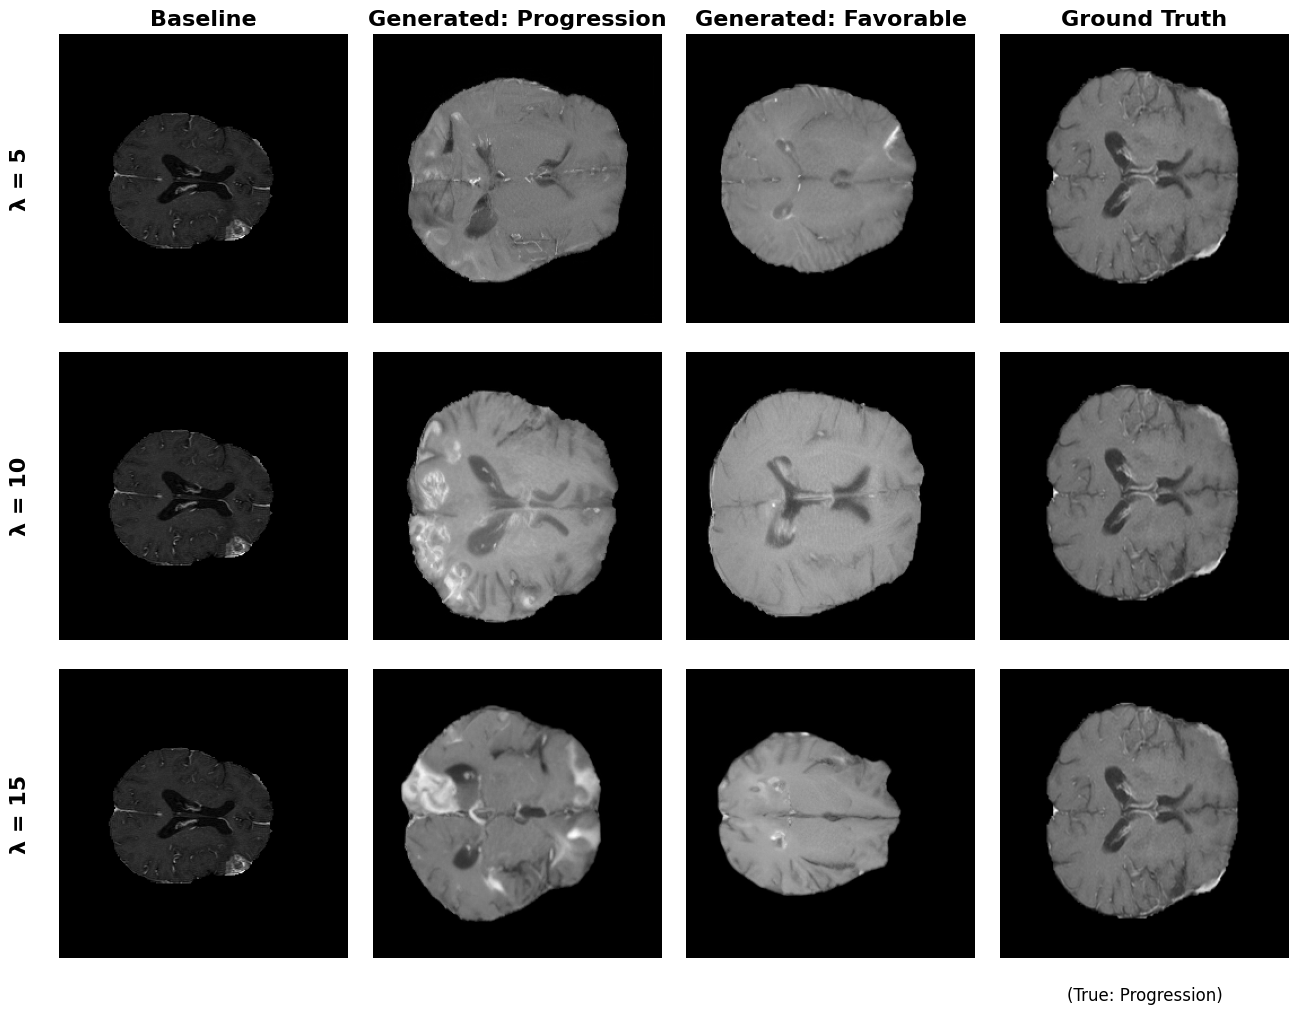

In [21]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import os

# ===================================================================
# 1. ユーザー設定
# ===================================================================
device = "cuda" if torch.cuda.is_available() else "cpu"

TARGET_PATIENT_ID = "YG_1HLO67MPZTJ9"
SAVE_DIR = "./paper_figures"
os.makedirs(SAVE_DIR, exist_ok=True)
SAVE_PATH = os.path.join(SAVE_DIR, "Fig4_Lambda_Comparison.eps")

# 各モデルの重み（.pth）へのパス
MODEL_PATHS = {
    "λ = 5":  "/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ5/best_model_epoch_136.pth",
    "λ = 10": "/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ10/best_model_epoch_147.pth",
    "λ = 15": "/home/masaki/mystudy/trained_models_masked_loss_l+c+Lmask_150_λ15/best_model_epoch_131.pth"
}

print(f"Targeting patient: {TARGET_PATIENT_ID}")

# ===================================================================
# 2. 対象患者データの検索
# ===================================================================
target_data = None
print("Searching for target patient in the dataloader...")
for batch in test_dataloader_gt:
    filename = batch["baseline_filename"][0]
    if TARGET_PATIENT_ID in filename:
        target_data = {
            "baseline_image": batch["baseline_image"].to(device),
            "future_image": batch["future_image"].to(device),
            "condition": batch["condition_label"][0]
        }
        print(f"Found patient: {TARGET_PATIENT_ID} (True Label: {target_data['condition']})")
        break

if target_data is None:
    print(f"❌ Error: Patient {TARGET_PATIENT_ID} not found in the test dataset.")
else:
    # ===================================================================
    # 3. 描画の準備と画像生成
    # ===================================================================
    fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))
    
    base_np = (target_data["baseline_image"][0, 0].cpu().numpy() / 2 + 0.5).clip(0, 1)
    real_np = (target_data["future_image"][0, 0].cpu().numpy() / 2 + 0.5).clip(0, 1)
    gt_condition = target_data["condition"]

    def to_numpy_img(out):
        if isinstance(out, list): out = out[0]
        if isinstance(out, torch.Tensor):
            return (out[0, 0].cpu().numpy() / 2 + 0.5).clip(0, 1)
        else:
            return np.array(out.convert("L")) / 255.0

    # ===================================================================
    # 4. モデルごとに推論とプロット
    # ===================================================================
    for row_idx, (model_name, weight_path) in enumerate(MODEL_PATHS.items()):
        print(f"\n--- Processing {model_name} ---")
        
        # ★ここを修正しました： model.controlnet に重みをロードする
        model.controlnet.load_state_dict(torch.load(weight_path, map_location=device))
        model.eval()

        # 画像生成
        prog_out = generate_future_image(model, target_data["baseline_image"], "Progression")
        fav_out = generate_future_image(model, target_data["baseline_image"], "Favorable Outcome")
        
        prog_np = to_numpy_img(prog_out)
        fav_np = to_numpy_img(fav_out)

        # --- プロット ---
        # 1列目: Baseline
        axes[row_idx, 0].imshow(base_np, cmap='gray')
        axes[row_idx, 0].axis('off')
        if row_idx == 0: axes[row_idx, 0].set_title("Baseline", fontsize=16, fontweight='bold')
        axes[row_idx, 0].text(-0.1, 0.5, f"{model_name}", ha="right", va="center", 
                              transform=axes[row_idx, 0].transAxes, fontsize=16, fontweight='bold', rotation=90)
        
        # 2列目: Generated Progression
        axes[row_idx, 1].imshow(prog_np, cmap='gray')
        axes[row_idx, 1].axis('off')
        if row_idx == 0: axes[row_idx, 1].set_title("Generated: Progression", fontsize=16, fontweight='bold')
        
        # 3列目: Generated Favorable
        axes[row_idx, 2].imshow(fav_np, cmap='gray')
        axes[row_idx, 2].axis('off')
        if row_idx == 0: axes[row_idx, 2].set_title("Generated: Favorable", fontsize=16, fontweight='bold')
        
        # 4列目: Ground Truth
        axes[row_idx, 3].imshow(real_np, cmap='gray')
        axes[row_idx, 3].axis('off')
        axes[row_idx, 3].text(0.5, -0.1, f"(True: {gt_condition})", ha="center", va="top", 
                              transform=axes[row_idx, 3].transAxes, fontsize=12)
        if row_idx == 0: axes[row_idx, 3].set_title("Ground Truth", fontsize=16, fontweight='bold')

    # 余白の調整
    plt.subplots_adjust(wspace=0.05, hspace=0.1)

    # EPS形式で保存
    plt.savefig(SAVE_PATH, format="eps", dpi=300, bbox_inches='tight')
    print(f"\n✅ Figure successfully saved to {SAVE_PATH}")
    plt.show()